# Qwen Zero-Shot Intent Classifier v4 - Single Token Generation

**The correct fix:** max_new_tokens=1 with NO LogitsProcessor.
- Model generates exactly 1 token - its genuine best guess
- 1 token = repetition is impossible
- No masking = no frequency bias
- If token matches a label first-token directly, done
- If not (rare edge case), fall back to logit argmax over 5 label tokens

In [ ]:
!pip install -q transformers accelerate pandas scikit-learn matplotlib seaborn

In [ ]:
import os, re, json, time
import torch
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# CONFIG
DATA_PATH        = "/content/drive/MyDrive/conversation_en.json"
MODEL_NAME       = "Qwen/Qwen2.5-1.5B-Instruct"
RANDOM_STATE     = 42
TEST_SIZE        = 0.20
VALID_LABELS     = ["Chitchat", "Interpret", "Reveal", "Revise", "Inquire"]
OUTPUT_PREFIX    = "qwen2_5_1_5b_v4_singletoken"
MAX_TEST_SAMPLES = None

print("CUDA available:", torch.cuda.is_available())
print("Model        :", MODEL_NAME)

CUDA available: True
Model        : Qwen/Qwen2.5-1.5B-Instruct


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# LOAD DATA
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

all_rows = []
for conv in raw:
    conv_id = str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        all_rows.append({
            "conversation_id": conv_id,
            "turn_index"     : int(i),
            "role"           : str(t.get("role", "")).lower(),
            "text"           : t.get("content") or "",
            "intent"         : t.get("intent"),
        })

df_turns_full = (
    pd.DataFrame(all_rows)
    .sort_values(["conversation_id", "turn_index"])
    .reset_index(drop=True)
)
df_turns_full["conversation_id"] = df_turns_full["conversation_id"].astype(str)
df_turns_full["turn_index"]      = df_turns_full["turn_index"].astype(int)
df_turns_full["role"]            = df_turns_full["role"].astype(str).str.lower()
df_turns_full["text"]            = df_turns_full["text"].fillna("").astype(str)

target_df = df_turns_full[
    (df_turns_full["role"] == "user") &
    (df_turns_full["intent"].notna()) &
    (df_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

print("Full rows            :", len(df_turns_full))
print("Target rows          :", len(target_df))
print("Unique conversations :", df_turns_full["conversation_id"].nunique())

Full rows            : 5633
Target rows          : 3196
Unique conversations : 826


In [ ]:
# SPLIT
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(target_df, groups=target_df["conversation_id"]))

train_df = target_df.iloc[train_idx].reset_index(drop=True)
test_df  = target_df.iloc[test_idx].reset_index(drop=True)

if MAX_TEST_SAMPLES is not None:
    test_df = test_df.head(MAX_TEST_SAMPLES).copy().reset_index(drop=True)

turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in df_turns_full.groupby("conversation_id")
}

print("Train rows:", len(train_df), "| Test rows:", len(test_df))
print("Overlap   :", len(set(train_df["conversation_id"]) & set(test_df["conversation_id"])))

Train rows: 2544 | Test rows: 652
Overlap   : 0


In [ ]:
sample_cid = test_df.iloc[0]["conversation_id"]

print("\nsample data")

full_conv = df_turns_full[df_turns_full["conversation_id"] == sample_cid]

print(full_conv[["turn_index", "role", "text", "intent"]].to_string(index=False))


sample data
 turn_index   role                                                                     text intent
          0   user                                                  I want a model airplane Reveal
          1 system                                                   Okay, these are great.   None
          2 system What type of model airplane do you want, such as the Airplane Boeing 747   None
          3   user                                                 I want something bigger. Reveal
          4 system                                        Okay, here are some bigger models   None
          5   user                                                                       ok Reveal


In [ ]:
print("\n--- TEST SAMPLE (USER TURNS ONLY) ---")
print(test_df[["conversation_id", "turn_index", "role", "text", "intent"]].head(10))


--- TEST SAMPLE (USER TURNS ONLY) ---
  conversation_id  turn_index  role                              text  \
0          100485           0  user           I want a model airplane   
1          100485           3  user          I want something bigger.   
2          100485           5  user                                ok   
3          100796           0  user                               hi!   
4          100796           2  user               I wanna a bicycle!!   
5          100796           4  user     for man. it should look good!   
6          100796           6  user             the last one is good!   
7          100891           0  user  I want to buy an electronic lock   
8          100891           2  user           The second one  is best   
9          101059           0  user         I want a cotton slippers.   

      intent  
0     Reveal  
1     Reveal  
2     Reveal  
3   Chitchat  
4     Reveal  
5  Interpret  
6  Interpret  
7     Reveal  
8  Interpret  
9     R

In [ ]:
# HISTORY BUILDER
def build_history_and_current_turn(full_conv, current_turn_index):
    history_df = full_conv[full_conv["turn_index"] < current_turn_index].copy()
    current_df = full_conv[
        (full_conv["turn_index"] == current_turn_index) & (full_conv["role"] == "user")
    ].copy()
    history_lines = []
    for _, row in history_df.iterrows():
        role = str(row["role"]).upper().strip()
        text = str(row["text"]).strip()
        if text:
            history_lines.append(f"{role}: {text}")
    history_text      = "\n".join(history_lines)
    current_turn_text = str(current_df.iloc[0]["text"]).strip() if len(current_df) > 0 else ""
    return history_text, current_turn_text

In [ ]:
# PROMPT
SYSTEM_PROMPT = """You are an intent classifier for product-search conversations.
Classify the CURRENT USER TURN into exactly one of these five labels:

  Chitchat  - greeting, thanks, or off-topic social talk
  Interpret - user answers, clarifies, or refines in response to prior conversation
  Reveal    - user introduces a new requirement, need, or preference
  Revise    - user changes or corrects a previously stated preference
  Inquire   - user asks a question about a product or system response

Rules:
- Use conversation history only as context.
- Classify ONLY the current user turn.
- Output ONLY the label word. No punctuation. No explanation."""

In [ ]:
# LOAD MODEL
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True,
)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token       = tokenizer.eos_token
    model.config.pad_token_id = tokenizer.eos_token_id
model.eval()
print("Model loaded on:", next(model.parameters()).device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded on: cuda:0


In [ ]:
# LABEL TOKEN SETUP
print("Label -> first token mapping:")
label_token_ids = []
for label in VALID_LABELS:
    ids = tokenizer.encode(label, add_special_tokens=False)
    label_token_ids.append(ids[0])
    print(f"  {label:12s} -> token_id={ids[0]:6d}  ({repr(tokenizer.decode([ids[0]]))})")

assert len(set(label_token_ids)) == len(VALID_LABELS), "Two labels share same first token!"
print("\nAll first tokens unique - safe to proceed.")
token_to_label = {tid: label for tid, label in zip(label_token_ids, VALID_LABELS)}

Label -> first token mapping:
  Chitchat     -> token_id=  1143  ('Ch')
  Interpret    -> token_id=  3306  ('Inter')
  Reveal       -> token_id=   693  ('Re')
  Revise       -> token_id= 36184  ('Rev')
  Inquire      -> token_id=   641  ('In')

All first tokens unique - safe to proceed.


In [ ]:
# PREDICT - single token
def predict_label(history_text, current_turn_text):
    user_content = (
        f"Conversation history:\n{history_text if history_text.strip() else 'None'}\n\n"
        f"Current user turn:\n{current_turn_text}\n\n"
        f"Choose one label: Chitchat | Interpret | Reveal | Revise | Inquire"
    )
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user",   "content": user_content},
    ]
    try:
        text   = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = tokenizer(text, return_tensors="pt").to(model.device)

        # Generate exactly 1 token
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=1,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
            )

        generated_token_id = outputs[0][-1].item()
        raw_output = tokenizer.decode([generated_token_id], skip_special_tokens=True).strip()

        # model naturally output a label first-token
        if generated_token_id in token_to_label:
            return token_to_label[generated_token_id], raw_output, "direct"

        # Fallback: model output whitespace/punctuation etc.
        with torch.no_grad():
            logits = model(**inputs).logits[0, -1, :]
        label_logits = torch.tensor([logits[tid].item() for tid in label_token_ids])
        best_idx     = label_logits.argmax().item()
        return VALID_LABELS[best_idx], raw_output, "fallback"

    except Exception as e:
        return "ERROR", str(e), "error"

In [ ]:
# SANITY CHECK
print("--- Quick 10-sample check ---")
debug = []
for row in test_df.head(10).itertuples(index=False):
    conv_df           = turns_by_conv_full[row.conversation_id]
    h, c              = build_history_and_current_turn(conv_df, row.turn_index)
    pred, raw, method = predict_label(h, c)
    debug.append({"true": row.intent, "pred": pred, "raw": repr(raw), "method": method})

debug_df = pd.DataFrame(debug)
print(debug_df.to_string(index=False))
print("\nPred distribution :", debug_df["pred"].value_counts().to_dict())
print("Direct vs fallback:", debug_df["method"].value_counts().to_dict())

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


--- Quick 10-sample check ---
     true      pred     raw method
   Reveal    Reveal    'Re' direct
   Reveal    Reveal    'Re' direct
   Reveal Interpret 'Inter' direct
 Chitchat  Chitchat    'Ch' direct
   Reveal    Reveal    'Re' direct
Interpret    Reveal    'Re' direct
Interpret    Reveal    'Re' direct
   Reveal    Reveal    'Re' direct
Interpret    Reveal    'Re' direct
   Reveal    Reveal    'Re' direct

Pred distribution : {'Reveal': 8, 'Interpret': 1, 'Chitchat': 1}
Direct vs fallback: {'direct': 10}


In [ ]:
# FULL INFERENCE LOOP
results    = []
n_direct   = 0
n_fallback = 0

for i, row in enumerate(test_df.itertuples(index=False), start=1):
    conv_df           = turns_by_conv_full[row.conversation_id]
    h, c              = build_history_and_current_turn(conv_df, row.turn_index)
    pred, raw, method = predict_label(h, c)

    if method == "direct": n_direct += 1
    else: n_fallback += 1

    results.append({
        "model_name"        : MODEL_NAME,
        "conversation_id"   : row.conversation_id,
        "turn_index"        : row.turn_index,
        "current_turn_text" : c,
        "intent"            : row.intent,
        "predicted_label"   : pred,
        "raw_token"         : raw,
        "method"            : method,
    })

    if i % 20 == 0 or i == len(test_df):
        print(f"Processed {i}/{len(test_df)} | direct={n_direct} fallback={n_fallback}")
        pd.DataFrame(results).to_csv(f"{OUTPUT_PREFIX}_predictions.csv", index=False)

pred_df = pd.DataFrame(results)
pred_df.to_csv(f"{OUTPUT_PREFIX}_predictions.csv", index=False)
print(f"\nDirect  : {n_direct}/{len(pred_df)} ({100*n_direct/len(pred_df):.1f}%)")
print(f"Fallback: {n_fallback}/{len(pred_df)} ({100*n_fallback/len(pred_df):.1f}%)")
print("\nPrediction distribution:")
print(pred_df["predicted_label"].value_counts())

Processed 20/652 | direct=20 fallback=0
Processed 40/652 | direct=40 fallback=0
Processed 60/652 | direct=60 fallback=0
Processed 80/652 | direct=80 fallback=0
Processed 100/652 | direct=100 fallback=0
Processed 120/652 | direct=120 fallback=0
Processed 140/652 | direct=140 fallback=0
Processed 160/652 | direct=160 fallback=0
Processed 180/652 | direct=180 fallback=0
Processed 200/652 | direct=200 fallback=0
Processed 220/652 | direct=220 fallback=0
Processed 240/652 | direct=240 fallback=0
Processed 260/652 | direct=260 fallback=0
Processed 280/652 | direct=280 fallback=0
Processed 300/652 | direct=300 fallback=0
Processed 320/652 | direct=320 fallback=0
Processed 340/652 | direct=340 fallback=0
Processed 360/652 | direct=360 fallback=0
Processed 380/652 | direct=380 fallback=0
Processed 400/652 | direct=400 fallback=0
Processed 420/652 | direct=420 fallback=0
Processed 440/652 | direct=440 fallback=0
Processed 460/652 | direct=460 fallback=0
Processed 480/652 | direct=480 fallback=0


In [ ]:
# EVALUATION
y_true = pred_df["intent"]
y_pred = pred_df["predicted_label"]

report_text = classification_report(y_true, y_pred, labels=VALID_LABELS, digits=3, zero_division=0)
report_dict = classification_report(y_true, y_pred, labels=VALID_LABELS, digits=3, zero_division=0, output_dict=True)

print("=== CLASSIFICATION REPORT ===")
print(report_text)

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.574     0.609     0.591        64
   Interpret      0.689     0.082     0.147       378
      Reveal      0.344     0.679     0.456       193
      Revise      0.000     0.000     0.000        12
     Inquire      0.000     0.000     0.000         5

    accuracy                          0.308       652
   macro avg      0.321     0.274     0.239       652
weighted avg      0.557     0.308     0.278       652



                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              39               5           11            0   
true_Interpret             28              31          225            0   
true_Reveal                 0               8          131            0   
true_Revise                 1               1            9            0   
true_Inquire                0               0            5            0   

                pred_Inquire  
true_Chitchat              9  
true_Interpret            94  
true_Reveal               54  
true_Revise                1  
true_Inquire               0  


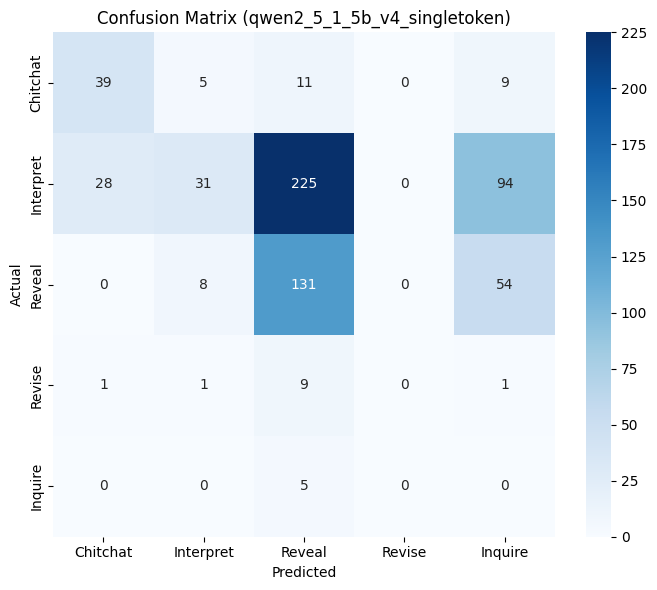


=== TOP CONFUSED PAIRS ===
   intent predicted_label  count
Interpret          Reveal    225
Interpret         Inquire     94
   Reveal         Inquire     54
Interpret        Chitchat     28
 Chitchat          Reveal     11
 Chitchat         Inquire      9
   Revise          Reveal      9
   Reveal       Interpret      8
 Chitchat       Interpret      5
  Inquire          Reveal      5
   Revise        Chitchat      1
   Revise         Inquire      1
   Revise       Interpret      1


In [ ]:
# CONFUSION MATRIX
cm = confusion_matrix(y_true, y_pred, labels=VALID_LABELS)
print(pd.DataFrame(cm,
    index   = [f"true_{x}" for x in VALID_LABELS],
    columns = [f"pred_{x}" for x in VALID_LABELS]))

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=VALID_LABELS, yticklabels=VALID_LABELS, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix ({OUTPUT_PREFIX})")
plt.tight_layout()
plt.savefig(f"{OUTPUT_PREFIX}_cm.png", dpi=300, bbox_inches="tight")
plt.show()

errors   = pred_df[pred_df["intent"] != pred_df["predicted_label"]].copy()
confused = (
    errors.groupby(["intent", "predicted_label"])
    .size().reset_index(name="count")
    .sort_values("count", ascending=False)
)
print("\n=== TOP CONFUSED PAIRS ===")
print(confused.head(15).to_string(index=False))

In [ ]:
# SAVE SUMMARY
summary = {
    "model"      : MODEL_NAME,
    "method"     : "zero-shot single-token generation",
    "total_test" : len(pred_df),
    "n_direct"   : n_direct,
    "n_fallback" : n_fallback,
    "accuracy"   : report_dict["accuracy"],
    "macro_f1"   : report_dict["macro avg"]["f1-score"],
    "per_class"  : {k: v for k, v in report_dict.items() if k in VALID_LABELS},
}
with open(f"{OUTPUT_PREFIX}_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "model": "Qwen/Qwen2.5-1.5B-Instruct",
  "method": "zero-shot single-token generation",
  "total_test": 652,
  "n_direct": 651,
  "n_fallback": 1,
  "accuracy": 0.30828220858895705,
  "macro_f1": 0.23878543759187246,
  "per_class": {
    "Chitchat": {
      "precision": 0.5735294117647058,
      "recall": 0.609375,
      "f1-score": 0.5909090909090909,
      "support": 64.0
    },
    "Interpret": {
      "precision": 0.6888888888888889,
      "recall": 0.082010582010582,
      "f1-score": 0.14657210401891252,
      "support": 378.0
    },
    "Reveal": {
      "precision": 0.3438320209973753,
      "recall": 0.6787564766839378,
      "f1-score": 0.4564459930313589,
      "support": 193.0
    },
    "Revise": {
      "precision": 0.0,
      "recall": 0.0,
      "f1-score": 0.0,
      "support": 12.0
    },
    "Inquire": {
      "precision": 0.0,
      "recall": 0.0,
      "f1-score": 0.0,
      "support": 5.0
    }
  }
}
